# 9e. ENSO and QBO background state of the vortex forecasts

In what tropical background do the forecasts put the 2026/27 vortex, and do the members' vortices vary with it?

1. **QBO**: equatorial zonal wind of each start against ERA5 (time-height and 50 hPa).
2. **Background state by start and case**: DJF Niño3.4 and Oct-Nov equatorial wind at 30 and 50 hPa.
3. **Member covariation within each start and case** (group means removed), so the differences
   between starts do not enter the fit.

This describes the forecast sample; it is not a test of the ENSO and Holton-Tan pathways, which needs a
long hindcast record. No ENSO × QBO interaction is fitted.

**Findings.** DJF Niño3.4 +2.4 to +4.7 °C (a very strong El Niño) with a westerly autumn-2026 QBO in every
member (U50 about +13 m/s): opposing influences, consistent with the near-normal vortex of 9c. The QBO
turns easterly for 2027/28 in nearly every member, without a weaker vortex. Within groups the member
vortex barely covaries with either (Niño3.4 r = +0.13, QBO r = -0.08).

**The 9a-9i series** (polar vortex and SSWs in the RTENSO2026 2026 starts): `9a` builds and checks the
caches; `9b` model climatology; `9c` vortex forecast; `9d` SSW occurrence; `9e` ENSO/QBO background;
`9f` SSW dynamics; `9g` SSW mechanism (featured member vs controls); `9h` SSW-event animation; `9i`
seasonal-evolution animation. Shared loading: `util/strat_diag.py`; readers `util/strat_case.py`; maps
`util/vortex_plot.py`.

In [1]:
%matplotlib inline

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from util import rtenso_case as rc
from util import strat_case as sc
from util import strat_diag as sd

warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")

### Run controls

In [2]:
NOTEBOOK = "9e_enso_qbo_background"   # outputs: rc.OUTPUT_ROOT/9e_enso_qbo_background/{figures,data}/
# "require": read the caches built by 9a only; "auto": build a missing cache; "rebuild": recompute
derivation_mode = "require"
CLIM_METHOD = "direct"      # model climatology: "direct" (each start's Reanalysis starts; Feb/Aug 1985-2010), "lead_drift"
WORKERS = 4                 # processes reading model output (cache builds only; login node: 30 GB per user)

# Data locations (machine-specific)
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                       # reference-data archive
ERA5_ZONAL_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily_zonal"                    # ERA5 daily zonal means
ERA5_DAILY_DIR = OBSERVATION_ROOT / "ERA5" / "1x1" / "daily"                          # ERA5 daily maps (PSL)
SIMULATION_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/simulation")         # raw eam.h1 history

cfg = sd.StratConfig(era5_zonal_dir=ERA5_ZONAL_DIR, era5_daily_dir=ERA5_DAILY_DIR, simulation_root=SIMULATION_ROOT,
                     clim_method=CLIM_METHOD, mode=derivation_mode, workers=WORKERS)
YEAR, INIT_MONTHS, POOL, CLIM_YEARS = cfg.year, cfg.init_months, cfg.pool, cfg.clim_years
ERA5_FIRST_YEAR, REF_LEVEL, SSW = cfg.era5_first_year, cfg.ref_level, cfg.ssw
MONTH_NAMES, INIT_COLORS, MODEL_PREFIX = sd.MONTH_NAMES, sd.INIT_COLORS, rc.MODEL_PREFIX
QBO_LEVEL = 50.0
QBO_MONTHS = (10, 11)
ENSO_THRESHOLD = 0.5                # degC: El Nino threshold line
DJF = sd.DJF

fontz = 13
fig_type = "png"
fig_dpi = 200
plt.rcParams.update({"font.size": fontz, "axes.titlesize": fontz, "axes.labelsize": fontz,
                     "legend.fontsize": fontz * 0.8, "xtick.labelsize": fontz * 0.85, "ytick.labelsize": fontz * 0.85})
rng = np.random.default_rng(0)


def save(fig, *parts):
    path = rc.save_figure(fig, NOTEBOOK, *parts, dpi=fig_dpi, ext=fig_type)
    print(f"[FIGURE] {path}")


DATA_DIR = rc.output_dir(NOTEBOOK, "data")

### Load

In [3]:
%%time
E = sd.load_era5(cfg)                         # ERA5 daily zonal-mean indices and climatologies (cached)
era5, obs_end = E.fields, E.obs_end
e_u60, e_pcz, e_pct, e_vt, e_qbo, e_pch = E.u60, E.pcz, E.pct, E.vt, E.qbo, E.pch
clim_u60, std_u60, clim_pcz, std_pcz = E.clim_u60, E.std_u60, E.clim_pcz, E.std_pcz
e_month_clim, e_u60_month = E.month_clim, E.u60_month
on_days = sd.on_days

ERA5 daily zonal means 01 Jan 1979 - 30 Jun 2026
CPU times: user 2.88 s, sys: 993 ms, total: 3.87 s
Wall time: 40.4 s


In [4]:
R = sd.load_references(cfg)                   # Reanalysis monthly zonal means of every start month
ref, ref_direct, REF_ALL, MPLEV = R.ref, R.direct, R.all, R.plev
e_month_clim_m = e_month_clim.sel(plev=MPLEV)   # ERA5 on the model monthly levels

In [5]:
%%time
M = sd.load_model(cfg, E, R)                  # pooled 2026 starts: zonal means, climatologies, daily indices
monthly, daily, lead_clim, z_offset = M.monthly, M.daily, M.lead_clim, M.z_offset
m_u60, m_u60_clim, m_u60_adj, m_pch, m_vt = M.u60, M.u60_clim, M.u60_adj, M.pch, M.vt
mm_u60, mm_u60_anom, mm_qbo = M.mm_u60, M.mm_u60_anom, M.mm_qbo

mid_month, case_of, djf_mean = sd.mid_month, sd.case_of, sd.djf_mean
m_djf = sd.djf_vortex(cfg, M, R, E)          # {(start, winter): DJF U(60N, 10 hPa) anomaly per member}

[init Feb 2026] 20 members, daily 01 Feb 2026 - 31 Jan 2028; climatology: Reanalysis init02 6 starts 1985-2010 (every fifth year)


[init May 2026] 30 members, daily 01 May 2026 - 30 Apr 2028; climatology: Reanalysis init05 1981-2010


[init Aug 2026] 30 members, daily 01 Aug 2026 - 31 Jul 2028; climatology: Reanalysis init08 6 starts 1985-2010 (every fifth year)


[init Nov 2026] 30 members, daily 01 Nov 2026 - 31 Oct 2028; climatology: Reanalysis init11 1981-2010


CPU times: user 4.04 s, sys: 2.19 s, total: 6.23 s
Wall time: 29 s


### 1. QBO

Monthly zonal-mean U over 5°S-5°N: ERA5 (top), then the ensemble mean of each start with the ERA5
values over the same months as contours. The right panels show the `QBO_LEVEL` wind of every member
against ERA5. A forecast QBO that decays, or that stops descending, moves the Holton-Tan pathway
(easterly lower-stratospheric QBO, weaker vortex) away from the observed one.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9e_enso_qbo_background/figures/fig_qbo_2026.png


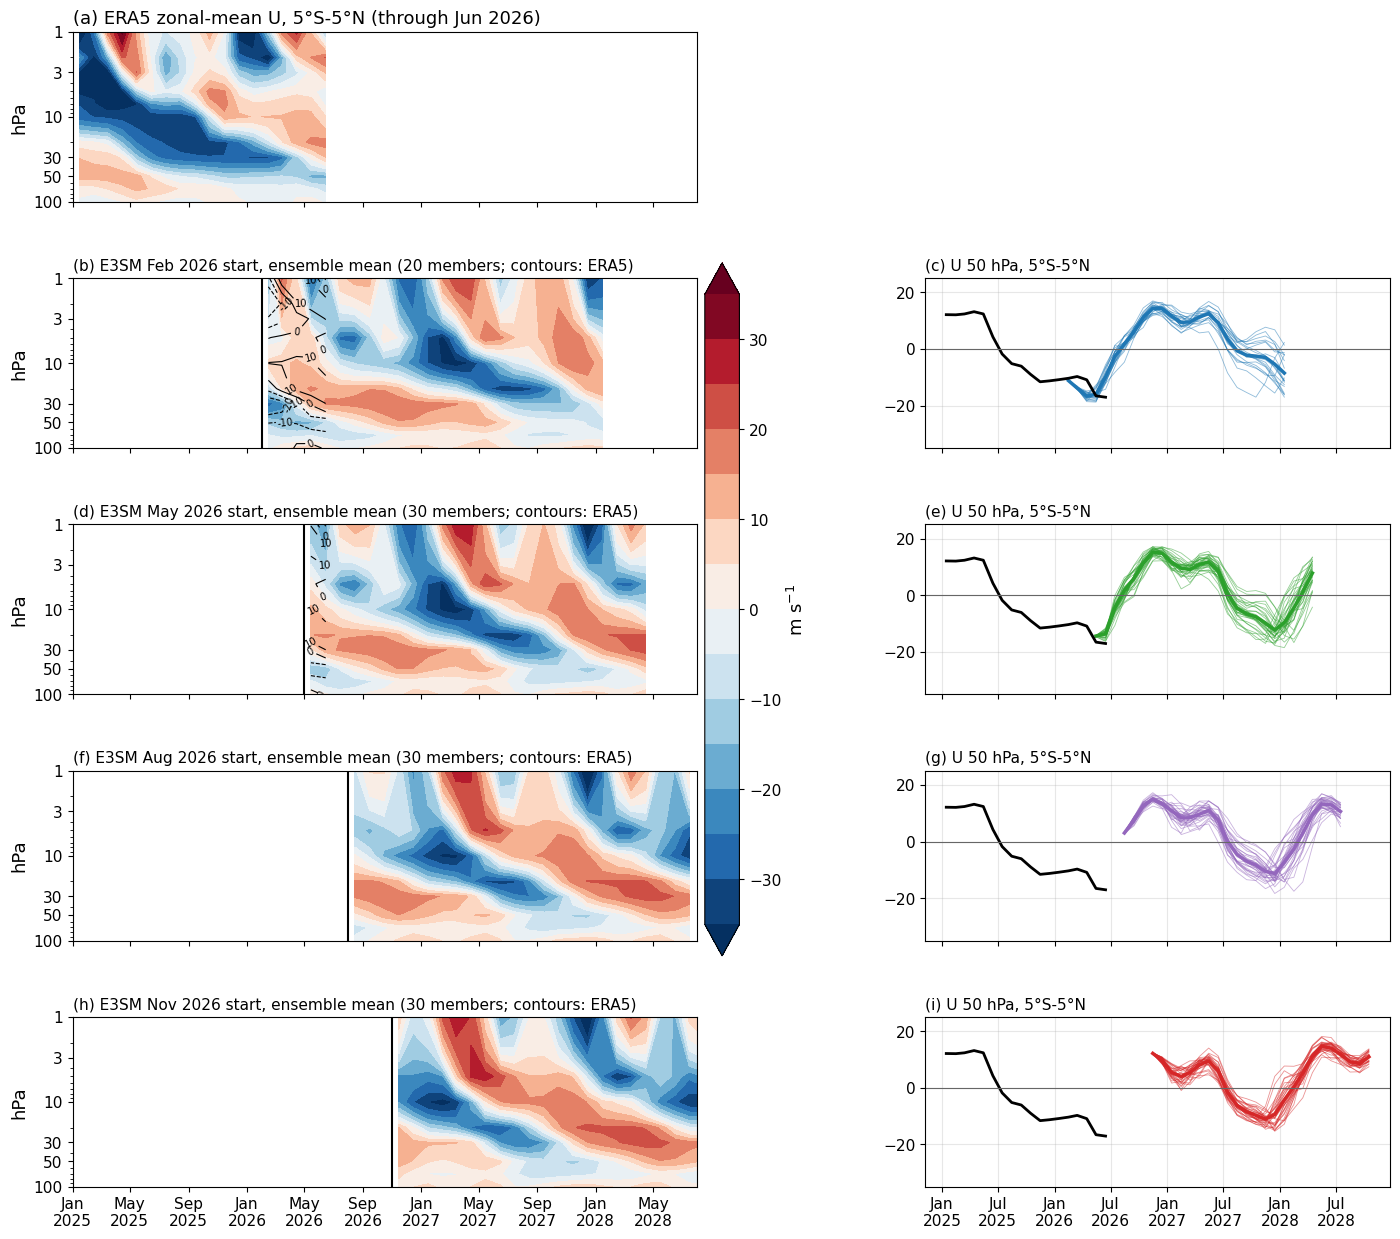

QBO 50 hPa over months (10, 11); ERA5 last observed autumn 2025: -10.3 m/s


,start,winter,U50 mean (m/s),members easterly,members
0,Feb,2026/27,12.7,0,20
1,Feb,2027/28,-2.8,14,20
2,May,2026/27,13.2,0,30
3,May,2027/28,-8.7,28,30
4,Aug,2026/27,13.8,0,30
5,Aug,2027/28,-9.5,30,30
6,Nov,2027/28,-10.4,30,30


In [6]:
qbo_span = (np.datetime64(f"{YEAR - 1}-01-01"), np.datetime64(f"{YEAR + 2}-08-01"))
fig, axes = plt.subplots(len(INIT_MONTHS) + 1, 2, figsize=(17, 3.0 * (len(INIT_MONTHS) + 1)),
                         gridspec_kw={"width_ratios": [1.6, 1], "hspace": 0.45, "wspace": 0.18}, sharex="col")
qlev = np.arange(-35, 36, 5)
eq = e_qbo.sel(time=slice(*qbo_span), plev=slice(1, 100))
ax = axes[0, 0]
cf = ax.contourf(eq["time"], eq["plev"], eq.T, levels=qlev, cmap="RdBu_r", extend="both")
ax.set_title(f"(a) ERA5 zonal-mean U, 5°S-5°N (through {obs_end:%b %Y})", loc="left")
axes[0, 1].axis("off")
for k, init in enumerate(INIT_MONTHS, start=1):
    q = mm_qbo[init].sel(plev=slice(1, 100))
    qt = q.assign_coords(time=monthly[init]["time"]).swap_dims(lead="time")
    ax = axes[k, 0]
    ax.contourf(qt["time"], qt["plev"], qt.mean("member").T, levels=qlev, cmap="RdBu_r", extend="both")
    ov = eq.sel(time=slice(qt["time"].values[0], qt["time"].values[-1]))
    if ov.sizes["time"] > 1:
        cs = ax.contour(ov["time"], ov["plev"], ov.T, levels=[-20, -10, 0, 10], colors="k", linewidths=0.8)
        ax.clabel(cs, fmt="%d", fontsize=fontz * 0.55)
    ax.axvline(np.datetime64(f"{YEAR}-{init:02d}-01"), color="k", lw=1.5)
    ax.set_title(f"({'abcdefghijklmnop'[2 * k - 1]}) E3SM {MONTH_NAMES[init]} {YEAR} start, ensemble mean "
                 f"({monthly[init].sizes['member']} members; contours: ERA5)", loc="left", fontsize=fontz * 0.85)
    ax2 = axes[k, 1]
    q50 = qt.sel(plev=QBO_LEVEL)
    for mem in q50["member"].values:
        ax2.plot(q50["time"], q50.sel(member=mem), color=INIT_COLORS[init], lw=0.6, alpha=0.5)
    ax2.plot(q50["time"], q50.mean("member"), color=INIT_COLORS[init], lw=2.5)
    e50 = e_qbo.sel(plev=QBO_LEVEL, time=slice(*qbo_span))
    ax2.plot(e50["time"], e50, "k-", lw=2)
    ax2.axhline(0, color="0.4", lw=0.8)
    ax2.set_ylim(-35, 25)
    ax2.set_title(f"({'abcdefghijklmnop'[2 * k]}) U {QBO_LEVEL:g} hPa, 5°S-5°N", loc="left", fontsize=fontz * 0.85)
    ax2.grid(alpha=0.3)
for ax in axes[:, 0]:
    ax.set_yscale("log")
    ax.set_ylim(100, 1)
    ax.set_yticks([100, 50, 30, 10, 3, 1], ["100", "50", "30", "10", "3", "1"])
    ax.set_ylabel("hPa")
    ax.set_xlim(*qbo_span)
for ax in axes[-1]:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.colorbar(cf, ax=axes[:, 0], label="m s$^{-1}$", shrink=0.6, pad=0.01)
save(fig, "qbo", YEAR)
plt.show()

# QBO phase before each forecast winter: member QBO_LEVEL wind over QBO_MONTHS
qbo_rows = []
for init in INIT_MONTHS:
    qt = mm_qbo[init].sel(plev=QBO_LEVEL).assign_coords(time=monthly[init]["time"]).swap_dims(lead="time")
    for w in (YEAR, YEAR + 1):
        sel = [t for t in pd.DatetimeIndex(qt["time"].values) if t.year == w and t.month in QBO_MONTHS]
        if len(sel) == len(QBO_MONTHS):
            v = qt.sel(time=sel).mean("time")
            qbo_rows.append({"start": MONTH_NAMES[init], "winter": f"{w}/{str(w + 1)[2:]}",
                             f"U{QBO_LEVEL:g} mean (m/s)": float(v.mean()), "members easterly": int((v < 0).sum()),
                             "members": int(v.size)})
e_qbo_on = {w: float(e_qbo.sel(plev=QBO_LEVEL).sel(time=[np.datetime64(f"{w}-{m:02d}-15") for m in QBO_MONTHS]).mean())
            for w in range(ERA5_FIRST_YEAR, YEAR + 1)
            if pd.Timestamp(f"{w}-{max(QBO_MONTHS):02d}-15") <= obs_end}
print(f"QBO {QBO_LEVEL:g} hPa over months {QBO_MONTHS}; ERA5 last observed autumn {max(e_qbo_on)}: {e_qbo_on[max(e_qbo_on)]:+.1f} m/s")
display(pd.DataFrame(qbo_rows).round(1))

### 2. Background state and member covariation

What tropical background the forecasts put the 2026/27 vortex in, **by start and case** (the
cases are different initial-state setups). This is a description of the forecast sample, not a test
of the ENSO and QBO teleconnections: the sampled ENSO and QBO ranges are narrow, and testing the
pathways (an average El Niño tendency to a weaker NH winter vortex; the Holton-Tan tendency to a
weaker vortex under an easterly lower-stratospheric QBO; both season- and background-dependent,
Holton and Tan 1980, Garfinkel and Hartmann 2007) needs a long hindcast record. No ENSO x QBO
interaction is fitted.

* **(a, b)** Member distributions of day-weighted DJF Niño3.4 (drift-corrected `TS`) and of the
  Oct-Nov equatorial (5°S-5°N) U at 30 and 50 hPa per start and case; ERA5 (Oct-Nov 2025, the last
  observed autumn) for reference on the QBO panel. The Niño3.4 evolution is in notebooks 1 and 8, the
  equatorial time-height sections in section 4.
* **(c, d)** Within-group centred member covariation: U'ᵢ − mean(U')_group against Xᵢ − mean(X)_group,
  so differences between starts and cases do not enter the fit.

,start,case,members,DJF Niño3.4 (°C),ON U30 (m/s),ON U50 (m/s),members U50 < 0,DJF vortex anomaly (m/s)
0,Feb,Reanalysis-CLIM,10,2.83,18.83,12.64,0,1.76
1,Feb,Reanalysis-NSIDC,10,2.39,19.11,12.80,0,1.28
2,May,Reanalysis-CLIM,10,3.57,18.92,13.34,0,1.74
3,May,Reanalysis-NSIDC,10,3.68,18.85,12.95,0,0.43
4,May,Reanalysis-OBS,10,3.68,19.11,13.39,0,1.01
5,Aug,Reanalysis-CLIM,10,4.64,18.54,14.08,0,1.62
6,Aug,Reanalysis-NSIDC,10,4.64,18.14,13.66,0,-1.18
7,Aug,Reanalysis-OBS,10,4.67,18.32,13.66,0,-0.51
8,Nov,Reanalysis-CLIM,10,3.81,NaN,NaN,0,-0.45
9,Nov,Reanalysis-NSIDC,10,3.79,NaN,NaN,0,0.34


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/9e_enso_qbo_background/figures/fig_background_enso_qbo_2026.png


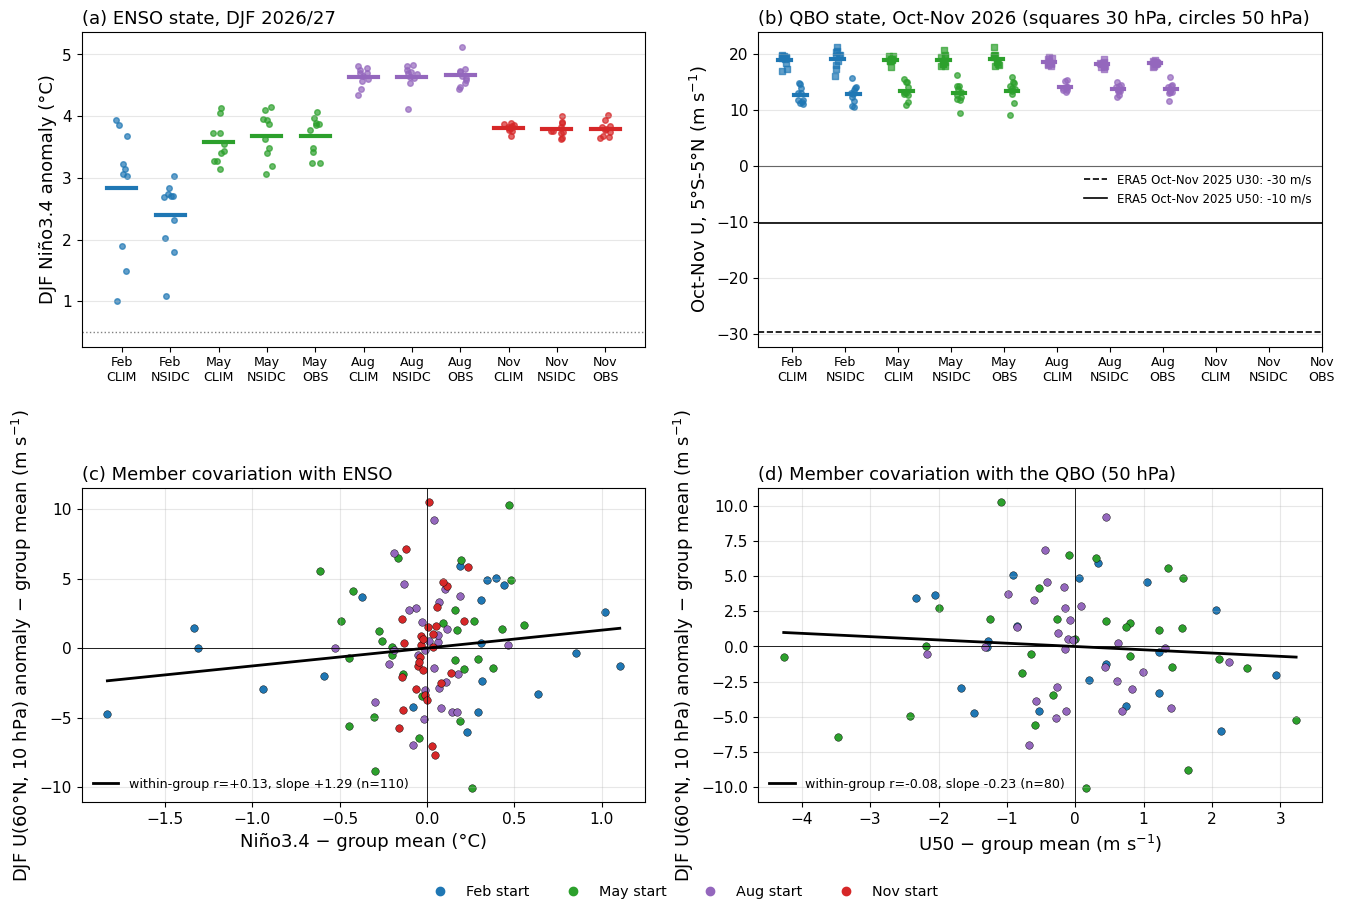

,predictor,set,n,r,slope
0,nino34,"E3SM 2026/27, within start x case",110,0.13,1.29
1,qbo50,"E3SM 2026/27, within start x case",80,-0.08,-0.23


In [7]:
w = YEAR
groups = {}                                        # (init, case) -> DataFrame of member values
for init in INIT_MONTHS:
    if (init, w) not in m_djf:
        continue
    vortex = m_djf[(init, w)].to_series()
    vortex.index = [str(i) for i in vortex.index]
    nino = {}
    for name, prefix in POOL.items():
        anom = rc.hindcast_anomaly(prefix, init, "TS", year=YEAR, method=CLIM_METHOD, mode=derivation_mode)
        if anom is None:
            continue
        n34 = rc.box_mean(anom, rc.NINO_REGIONS["Nino3.4"]).load()
        n34 = n34.assign_coords(time=("lead", mid_month(n34["time"].values))).swap_dims(lead="time")
        for mem in n34["member"].values:
            v = djf_mean(n34.sel(member=mem), w)
            nino[f"{name}:{mem}"] = np.nan if v is None else float(v)
    q = mm_qbo[init].assign_coords(time=monthly[init]["time"]).swap_dims(lead="time")
    qt = [np.datetime64(f"{w}-{m:02d}-15") for m in QBO_MONTHS]
    qon = q.sel(time=qt).mean("time") if all(t in q["time"].values for t in qt) else None
    df = pd.DataFrame({"vortex": vortex, "nino34": pd.Series(nino).reindex(vortex.index)})
    for p in (30.0, 50.0):
        s = qon.sel(plev=p).to_series() if qon is not None else pd.Series(np.nan, index=vortex.index)
        s.index = [str(i) for i in s.index]
        df[f"qbo{p:g}"] = s.reindex(vortex.index)
    df["case"] = [case_of(m) for m in df.index]
    for case, sub in df.groupby("case"):
        groups[(init, case)] = sub

summary = pd.DataFrame([{"start": MONTH_NAMES[i], "case": c, "members": len(g),
                         "DJF Niño3.4 (°C)": g["nino34"].mean(), "ON U30 (m/s)": g["qbo30"].mean(),
                         "ON U50 (m/s)": g["qbo50"].mean(), "members U50 < 0": int((g["qbo50"] < 0).sum()),
                         "DJF vortex anomaly (m/s)": g["vortex"].mean()} for (i, c), g in groups.items()])
display(summary.round(2))
e_qbo_last = {p: float(e_qbo.sel(plev=p).sel(time=[np.datetime64(f"{max(e_qbo_on)}-{m:02d}-15") for m in QBO_MONTHS]).mean())
              for p in (30.0, 50.0)}

fig, axes = plt.subplots(2, 2, figsize=(16, 10), gridspec_kw={"hspace": 0.45, "wspace": 0.2})
keys = list(groups)
glabel = [f"{MONTH_NAMES[i]}\n{c.replace('Reanalysis-', '')}" for i, c in keys]
gcol = [INIT_COLORS[i] for i, _ in keys]
x = np.arange(len(keys))
ax = axes[0, 0]
for xi, k, c in zip(x, keys, gcol):
    v = groups[k]["nino34"].dropna().values
    ax.scatter(np.full(v.size, xi) + rng.uniform(-0.12, 0.12, v.size), v, color=c, s=16, alpha=0.7)
    ax.plot([xi - 0.3, xi + 0.3], [v.mean()] * 2, color=c, lw=3)
ax.axhline(ENSO_THRESHOLD, color="0.5", ls=":", lw=1)
ax.set_xticks(x, glabel, fontsize=fontz * 0.7)
ax.set_ylabel("DJF Niño3.4 anomaly (°C)")
ax.set_title(f"(a) ENSO state, DJF {w}/{str(w + 1)[2:]}", loc="left")
ax.grid(alpha=0.3, axis="y")
ax = axes[0, 1]
for p, dx, mk in ((30.0, -0.15, "s"), (50.0, 0.15, "o")):
    for xi, k, c in zip(x, keys, gcol):
        v = groups[k][f"qbo{p:g}"].dropna().values
        ax.scatter(np.full(v.size, xi + dx) + rng.uniform(-0.05, 0.05, v.size), v, color=c, marker=mk, s=16, alpha=0.7)
        ax.plot([xi + dx - 0.12, xi + dx + 0.12], [v.mean()] * 2, color=c, lw=3)
    ax.axhline(e_qbo_last[p], color="k", ls="--" if p == 30 else "-", lw=1.2,
               label=f"ERA5 Oct-Nov {max(e_qbo_on)} U{p:g}: {e_qbo_last[p]:+.0f} m/s")
ax.axhline(0, color="0.4", lw=0.8)
ax.set_xticks(x, glabel, fontsize=fontz * 0.7)
ax.set_ylabel("Oct-Nov U, 5°S-5°N (m s$^{-1}$)")
ax.set_title(f"(b) QBO state, Oct-Nov {w} (squares 30 hPa, circles 50 hPa)", loc="left")
ax.legend(frameon=False, fontsize=fontz * 0.65)
ax.grid(alpha=0.3, axis="y")

reg_rows = []
for ax, (xkey, xl) in zip(axes[1], [("nino34", "Niño3.4 − group mean (°C)"), ("qbo50", f"U{QBO_LEVEL:g} − group mean (m s$^{{-1}}$)")]):
    allx, ally = [], []
    for k, c in zip(keys, gcol):
        g = groups[k].dropna(subset=["vortex", xkey])
        if len(g) < 3:
            continue
        dx, dy = g[xkey] - g[xkey].mean(), g["vortex"] - g["vortex"].mean()
        ax.scatter(dx, dy, color=c, s=30, edgecolor="k", lw=0.3)
        allx += list(dx)
        ally += list(dy)
    if len(allx) > 3:
        allx, ally = np.asarray(allx), np.asarray(ally)
        r = np.corrcoef(allx, ally)[0, 1]
        b = np.polyfit(allx, ally, 1)
        xx = np.linspace(allx.min(), allx.max(), 10)
        ax.plot(xx, np.polyval(b, xx), "k-", lw=2, label=f"within-group r={r:+.2f}, slope {b[0]:+.2f} (n={allx.size})")
        reg_rows.append({"predictor": xkey, "set": f"E3SM {w}/{str(w + 1)[2:]}, within start x case", "n": allx.size,
                         "r": r, "slope": b[0]})
    ax.axhline(0, color="k", lw=0.6)
    ax.axvline(0, color="k", lw=0.6)
    ax.set_xlabel(xl)
    ax.set_ylabel("DJF U(60°N, 10 hPa) anomaly − group mean (m s$^{-1}$)")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False, fontsize=fontz * 0.7, loc="lower left")
axes[1, 0].set_title("(c) Member covariation with ENSO", loc="left")
axes[1, 1].set_title(f"(d) Member covariation with the QBO ({QBO_LEVEL:g} hPa)", loc="left")
handles = [Line2D([], [], color=INIT_COLORS[i], marker="o", ls="", label=f"{MONTH_NAMES[i]} start") for i in dict.fromkeys(i for i, _ in keys)]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, bbox_to_anchor=(0.5, 0.0))
save(fig, "background", "enso", "qbo", YEAR)
plt.show()
display(pd.DataFrame(reg_rows).round(2))